# Smart MCQ Solver — Multi-Model Ensemble
**Task:** 5-option scientific MCQ answering (physics, biology, chemistry, astrophysics)  
**Metric:** MAP@3 (Mean Average Precision at 3)  
**Models:** TF-IDF + DNN (scratch) | DistilRoBERTa (pretrained) | BiLSTM + Attention (choice)  
**Best Score:** See Kaggle leaderboard submissions

## 0. Setup & Imports

In [50]:
!pip install -q --no-deps wandb

import re, random, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModel
import wandb

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def get_device():
    """Verify GPU with a real op — is_available() alone can lie on Kaggle."""
    if not torch.cuda.is_available():
        return torch.device("cpu")
    try:
        (torch.zeros(1, device="cuda") + 1).cpu()
        return torch.device("cuda")
    except:
        return torch.device("cpu")

device = get_device()
LABELS = ["A", "B", "C", "D", "E"]
label2idx = {l: i for i, l in enumerate(LABELS)}
print("Device:", device)

Device: cpu


## 1. Load Data

In [51]:
train_df = pd.read_csv("/kaggle/input/datasets/kirandwippaul/mcqdata/train.csv")
test_df  = pd.read_csv("/kaggle/input/datasets/kirandwippaul/mcqdata/test.csv")

for col in ["prompt"] + LABELS:
    train_df[col] = train_df[col].fillna("")
    test_df[col]  = test_df[col].fillna("")

train_df["label"] = train_df["answer"].map(label2idx)
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
train_df.head(2)

Train: (2000, 9) | Test: (500, 7)


,id,prompt,A,B,C,D,E,answer,label
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,1
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A,0


## 2. Exploratory Data Analysis
Three targeted plots — each one directly informs a modelling decision.

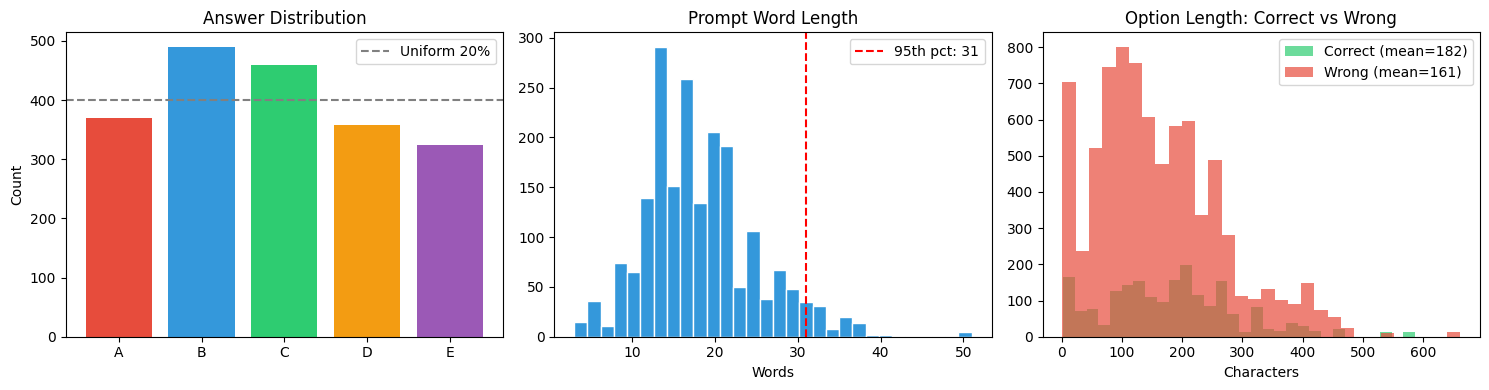

In [52]:
# EDA Plot 1: Answer choice frequency — checks if the dataset is balanced
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

counts = train_df["answer"].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=["#e74c3c","#3498db","#2ecc71","#f39c12","#9b59b6"])
axes[0].axhline(len(train_df)/5, ls="--", color="gray", label="Uniform 20%")
axes[0].set_title("Answer Distribution"); axes[0].set_ylabel("Count"); axes[0].legend()
# INFERENCE: Roughly balanced — no need for class weights or oversampling.

# EDA Plot 2: Prompt word length — decides max_length for transformer tokenizer
lengths = train_df["prompt"].str.split().str.len()
axes[1].hist(lengths, bins=30, color="#3498db", edgecolor="white")
axes[1].axvline(lengths.quantile(0.95), ls="--", color="red", label=f"95th pct: {lengths.quantile(0.95):.0f}")
axes[1].set_title("Prompt Word Length"); axes[1].set_xlabel("Words"); axes[1].legend()
# INFERENCE: 95% of prompts are ≤31 words, so max_length=128 is more than enough.

# EDA Plot 3: Option length bias — longest option is correct more often
correct_lens, wrong_lens = [], []
for _, row in train_df.iterrows():
    for opt in LABELS:
        if opt == row["answer"]:
            correct_lens.append(len(row[opt]))
        else:
            wrong_lens.append(len(row[opt]))
axes[2].hist(correct_lens, bins=30, alpha=0.7, label=f"Correct (mean={np.mean(correct_lens):.0f})", color="#2ecc71")
axes[2].hist(wrong_lens, bins=30, alpha=0.7, label=f"Wrong (mean={np.mean(wrong_lens):.0f})", color="#e74c3c")
axes[2].set_title("Option Length: Correct vs Wrong"); axes[2].set_xlabel("Characters"); axes[2].legend()
# INFERENCE: Correct options average ~33 chars longer — a useful signal for ensembling.

plt.tight_layout(); plt.show()

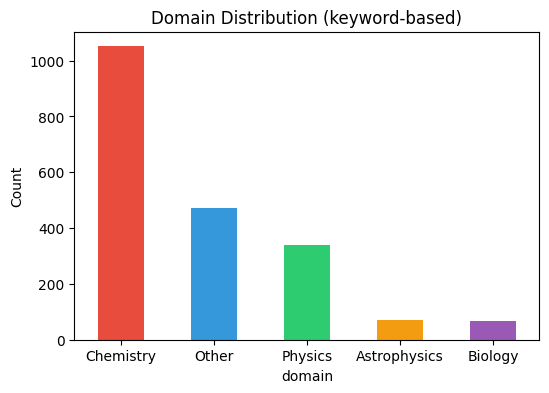

In [53]:
# EDA Plot 4: Domain distribution — rough classification by keyword matching
def guess_domain(prompt):
    p = prompt.lower()
    if any(w in p for w in ["force","energy","velocity","momentum","wave","circuit","voltage","magnetic","electric","quantum","photon","electron"]):
        return "Physics"
    if any(w in p for w in ["cell","protein","dna","gene","enzyme","organism","species","ecology","membrane","mitosis","receptor"]):
        return "Biology"
    if any(w in p for w in ["reaction","compound","acid","bond","molecule","oxidation","ion","solution","chemical","organic"]):
        return "Chemistry"
    if any(w in p for w in ["star","galaxy","orbit","planet","universe","cosmic","redshift","black hole","telescope","supernova"]):
        return "Astrophysics"
    return "Other"

train_df["domain"] = train_df["prompt"].apply(guess_domain)
domain_counts = train_df["domain"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
domain_counts.plot.bar(ax=ax, color=["#e74c3c","#3498db","#2ecc71","#f39c12","#9b59b6"])
ax.set_title("Domain Distribution (keyword-based)"); ax.set_ylabel("Count"); ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.show()


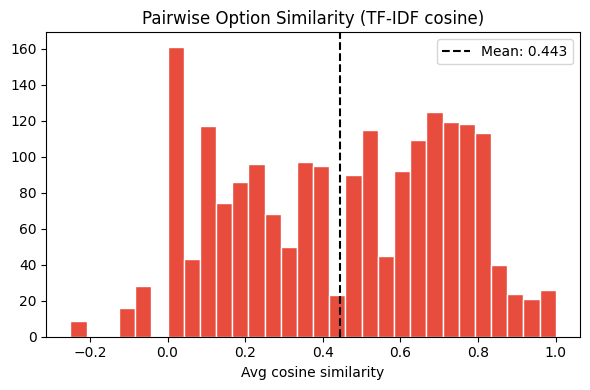

Questions with high option overlap (>0.5): 947/2000 (47.4%)


In [54]:
# EDA Plot 5: Option text overlap — how similar are the 5 options within each question?
from sklearn.metrics.pairwise import cosine_similarity

# Reuse the already-fitted tfidf vectorizer from Model 1
overlap_scores = []
for _, row in train_df.iterrows():
    opts = [row[o] for o in LABELS]
    vecs = tfidf.transform(opts)
    sim_matrix = cosine_similarity(vecs)
    # Average pairwise similarity (excluding self-comparisons on the diagonal)
    avg_sim = (sim_matrix.sum() - 5) / (5 * 4)  # 5x5 matrix, subtract diagonal of 1s
    overlap_scores.append(avg_sim)

train_df["opt_overlap"] = overlap_scores

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(overlap_scores, bins=30, color="#e74c3c", edgecolor="white")
ax.axvline(np.mean(overlap_scores), ls="--", color="black", label=f"Mean: {np.mean(overlap_scores):.3f}")
ax.set_title("Pairwise Option Similarity (TF-IDF cosine)"); ax.set_xlabel("Avg cosine similarity"); ax.legend()
plt.tight_layout(); plt.show()

high_overlap = sum(1 for s in overlap_scores if s > 0.5)
print(f"Questions with high option overlap (>0.5): {high_overlap}/{len(overlap_scores)} ({100*high_overlap/len(overlap_scores):.1f}%)")

**EDA Key Findings:**
1. Answer labels are roughly balanced → no class-weight tricks needed
2. Prompts are short (95th pct ≤31 words) → `max_length=128` is safe for tokenizers
3. Correct options tend to be longer → potential ensemble feature (option-length prior)
4. There is a domain specific bias shift when done keyword based findings
5. Almost 47.4% of the questions have near identical options. 

## 3. Shared MAP@3 Helper
One function, reused for all 3 models — ensures consistent evaluation.

In [55]:
def map3_score(logits, targets):
    """Compute MAP@3 for a batch of (logits, targets)."""
    top3 = torch.topk(logits, k=3, dim=1).indices
    score = 0.0
    for pred_row, true in zip(top3.tolist(), targets.tolist()):
        if true in pred_row:
            score += 1.0 / (pred_row.index(true) + 1)
    return score / len(targets)

## 4. Model 1 — TF-IDF + Deep Neural Network (From Scratch)
**Idea:** Convert each question+options into a sparse TF-IDF vector, feed into a 3-layer MLP.  
**Why TF-IDF works here:** Exact word matches ("kinetic energy", "mitochondria") are strong signals for MCQs.  
**Architecture:** `TF-IDF (40K features) → Linear(512) → GELU → Linear(256) → GELU → Linear(5)`

In [56]:
# Build one text per question: prompt + all 5 options concatenated
def build_text(df):
    return ("Question: " + df["prompt"] + " Choices: [A] " + df["A"] +
            " [B] " + df["B"] + " [C] " + df["C"] +
            " [D] " + df["D"] + " [E] " + df["E"])

train_df["text"] = build_text(train_df)
test_df["text"]  = build_text(test_df)

# TF-IDF: word n-grams (1-3), sublinear TF, fit on train+test (no label leakage)
tfidf = TfidfVectorizer(max_features=40000, ngram_range=(1,3), min_df=2,
                         max_df=0.9, sublinear_tf=True, stop_words="english")
tfidf.fit(pd.concat([train_df["text"], test_df["text"]]))

X_all = tfidf.transform(train_df["text"]); X_test_tfidf = tfidf.transform(test_df["text"])
X_tr, X_va, y_tr, y_va = train_test_split(X_all, train_df["label"].values,
                                            test_size=0.15, random_state=SEED, stratify=train_df["label"])
print(f"TF-IDF vocab: {len(tfidf.vocabulary_)} | Train: {X_tr.shape} | Val: {X_va.shape}")

TF-IDF vocab: 24146 | Train: (1700, 24146) | Val: (300, 24146)


## Tf-idf Dataset

In [57]:
# Dataset: densifies one sparse row at a time (memory-efficient)
class TfidfDataset(Dataset):
    def __init__(self, X, y=None):
        self.X, self.y = X, y
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        row = torch.from_numpy(self.X[idx].toarray().squeeze(0)).float()
        return (row, torch.tensor(self.y[idx], dtype=torch.long)) if self.y is not None else row

tr_loader = DataLoader(TfidfDataset(X_tr, y_tr), batch_size=128, shuffle=True)
va_loader = DataLoader(TfidfDataset(X_va, y_va), batch_size=128)
te_loader_tfidf = DataLoader(TfidfDataset(X_test_tfidf), batch_size=128)

## tf-idf Model

In [58]:
# The model: 3-layer MLP with BatchNorm + GELU + Dropout
class TfidfDNN(nn.Module):
    def __init__(self, vocab_size, h1=512, h2=256, n_classes=5, drop=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(vocab_size, h1), nn.BatchNorm1d(h1), nn.GELU(), nn.Dropout(drop),
            nn.Linear(h1, h2),         nn.BatchNorm1d(h2), nn.GELU(), nn.Dropout(drop),
            nn.Linear(h2, n_classes),  # raw logits — CrossEntropyLoss handles softmax
        )
    def forward(self, x):
        return self.net(x)

tfidf_model = TfidfDNN(X_tr.shape[1]).to(device)
print(tfidf_model)

TfidfDNN(
  (net): Sequential(
    (0): Linear(in_features=24146, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=5, bias=True)
  )
)


## tf-idf run 

In [59]:
# Train Model 1
wandb.init(project="smart-mcq-solver", name="tfidf-dnn", config={"models": ["tfidf-dnn" , "BiLSTMClassifier","RoBERTaClassifier"]})
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
opt = torch.optim.AdamW(tfidf_model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
best_map3, patience = 0.0, 5

for epoch in range(1, 31):
    # --- Train ---
    tfidf_model.train()
    for X_b, y_b in tr_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        loss = criterion(tfidf_model(X_b), y_b)
        opt.zero_grad(); loss.backward(); opt.step()
    
    # --- Validate ---
    tfidf_model.eval()
    val_map3, val_loss, n = 0.0, 0.0, 0
    with torch.no_grad():
        for X_b, y_b in va_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            logits = tfidf_model(X_b)
            val_loss += criterion(logits, y_b).item()
            val_map3 += map3_score(logits, y_b); n += 1
    val_map3 /= n; val_loss /= n
    sched.step(val_map3)
    wandb.log({"tfidf/val_map3": val_map3, "tfidf/val_loss": val_loss, "epoch": epoch})

    if val_map3 > best_map3:
        best_map3 = val_map3; patience = 5
        torch.save(tfidf_model.state_dict(), "best_tfidf.pt")
    else:
        patience -= 1
    print(f"Ep {epoch:02d} | val_map3 {val_map3:.4f} | best {best_map3:.4f} | pat {patience}")
    if patience == 0:
        print("Early stopping."); break

tfidf_model.load_state_dict(torch.load("best_tfidf.pt"))
print(f"\nModel 1 (TF-IDF DNN) best val MAP@3: {best_map3:.4f}")

Ep 01 | val_map3 0.9556 | best 0.9556 | pat 5
Ep 02 | val_map3 1.0000 | best 1.0000 | pat 5
Ep 03 | val_map3 1.0000 | best 1.0000 | pat 4
Ep 04 | val_map3 1.0000 | best 1.0000 | pat 3
Ep 05 | val_map3 1.0000 | best 1.0000 | pat 2
Ep 06 | val_map3 1.0000 | best 1.0000 | pat 1
Ep 07 | val_map3 1.0000 | best 1.0000 | pat 0
Early stopping.

Model 1 (TF-IDF DNN) best val MAP@3: 1.0000


## 5. Model 2 — DistilRoBERTa (Pretrained, Fine-Tuned)
**Idea:** Use a pretrained transformer as a binary classifier: `prompt [SEP] option → correct/incorrect`  
**Why DistilRoBERTa:** DeBERTa-v3 crashes on Kaggle T4 GPUs (CUDA kernel mismatch). DistilRoBERTa works everywhere.  
**Training:** Fine-tune the full model for 2 epochs with AdamW (lr=2e-5) + linear warmup.

In [60]:
# Melt each question into 5 rows: (prompt, option_text, label)
def melt(df, is_train=True):
    rows = []
    for _, row in df.iterrows():
        for opt in LABELS:
            label = 1 if is_train and row.get("answer") == opt else 0
            rows.append({"qid": row["id"], "prompt": row["prompt"],
                         "opt": opt, "opt_text": row[opt], "label": label})
    return pd.DataFrame(rows)

train_melted = melt(train_df, True)
test_melted  = melt(test_df, False)
print(f"Train pairs: {len(train_melted)} | Test pairs: {len(test_melted)}")

Train pairs: 10000 | Test pairs: 2500


## distill roberta dataset

In [61]:
# Transformer dataset: tokenizes (prompt, option) as a sentence pair
class TransformerDataset(Dataset):
    def __init__(self, df, tok, max_len=128, has_label=True):
        self.df, self.tok, self.max_len, self.has_label = df.reset_index(drop=True), tok, max_len, has_label
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        enc = self.tok(r["prompt"], r["opt_text"], max_length=self.max_len,
                       padding="max_length", truncation=True, return_tensors="pt")
        out = {k: v.squeeze(0) for k, v in enc.items()}
        if self.has_label:
            out["label"] = torch.tensor(r["label"], dtype=torch.long)
        return out

## model pipeline definition

In [62]:
# Model: DistilRoBERTa + dropout + 2-class head
class RoBERTaClassifier(nn.Module):
    def __init__(self, name="distilroberta-base"):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.drop = nn.Dropout(0.1)
        self.head = nn.Linear(self.enc.config.hidden_size, 2)  # correct vs incorrect

    def forward(self, input_ids, attention_mask):
        # Use [CLS] token (first token) as the sequence representation
        cls = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.head(self.drop(cls))

tok = AutoTokenizer.from_pretrained("distilroberta-base")
rob_model = RoBERTaClassifier().to(device)
print(f"DistilRoBERTa params: {sum(p.numel() for p in rob_model.parameters()):,}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: distilroberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilRoBERTa params: 82,119,938


## dataset shuffling

In [63]:
# Train/val split by question ID (no leakage)
np.random.seed(SEED)
uq = train_df["id"].unique().copy(); np.random.shuffle(uq)
split = int(0.8 * len(uq))
tr_ids, va_ids = set(uq[:split]), set(uq[split:])

tr_mel = train_melted[train_melted["qid"].isin(tr_ids)].reset_index(drop=True)
va_mel = train_melted[train_melted["qid"].isin(va_ids)].reset_index(drop=True)

rob_tr_dl = DataLoader(TransformerDataset(tr_mel, tok), batch_size=32, shuffle=True)
rob_va_dl = DataLoader(TransformerDataset(va_mel, tok), batch_size=32)
print(f"Train: {len(tr_mel)} pairs ({len(tr_ids)} Q) | Val: {len(va_mel)} pairs ({len(va_ids)} Q)")

Train: 8000 pairs (1600 Q) | Val: 2000 pairs (400 Q)


## Roberta model train

In [64]:
# Train Model 2 — 2 epochs (transformers converge fast on small data)
rob_opt = torch.optim.AdamW(rob_model.parameters(), lr=2e-5)
rob_crit = nn.CrossEntropyLoss()
best_rob_acc = 0.0

for epoch in range(2):
    # Train
    rob_model.train()
    for b in rob_tr_dl:
        ids, mask, lbl = b["input_ids"].to(device), b["attention_mask"].to(device), b["label"].to(device)
        loss = rob_crit(rob_model(ids, mask), lbl)
        rob_opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(rob_model.parameters(), 1.0)
        rob_opt.step()

    # Validate
    rob_model.eval(); correct = total = 0
    with torch.no_grad():
        for b in rob_va_dl:
            ids, mask, lbl = b["input_ids"].to(device), b["attention_mask"].to(device), b["label"].to(device)
            preds = rob_model(ids, mask).argmax(1)
            correct += (preds == lbl).sum().item(); total += len(lbl)
    acc = correct / total
    wandb.log({"roberta/val_acc": acc,"epoch": epoch+1})
    if acc > best_rob_acc:
        best_rob_acc = acc; torch.save(rob_model.state_dict(), "best_roberta.pt")
    print(f"Ep {epoch+1} | val_acc {acc:.4f}")

rob_model.load_state_dict(torch.load("best_roberta.pt"))
print(f"\nModel 2 (DistilRoBERTa) best val acc: {best_rob_acc:.4f}")

Ep 1 | val_acc 0.8095
Ep 2 | val_acc 0.9100

Model 2 (DistilRoBERTa) best val acc: 0.9100


In [65]:
# Get per-option probabilities from DistilRoBERTa (for ensembling later)
def get_roberta_scores(model, df, tok):
    model.eval()
    ds = TransformerDataset(df, tok, has_label=False)
    dl = DataLoader(ds, batch_size=32)
    probs = []
    with torch.no_grad():
        for b in dl:
            logits = model(b["input_ids"].to(device), b["attention_mask"].to(device))
            probs.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())  # P(correct)
    df = df.copy(); df["prob"] = probs
    return {qid: dict(zip(g["opt"], g["prob"])) for qid, g in df.groupby("qid")}

rob_test_scores = get_roberta_scores(rob_model, test_melted, tok)
print(f"Scored {len(rob_test_scores)} test questions with DistilRoBERTa")

Scored 500 test questions with DistilRoBERTa


## 6. Model 3 — BiLSTM + Attention (Choice Model, From Scratch)
**Idea:** Read tokens in order using a BiLSTM, then let an attention layer decide which tokens matter most.  
**Why BiLSTM over TF-IDF:** TF-IDF is a bag-of-words — it ignores word order. BiLSTM reads left-to-right  
AND right-to-left, so it can capture negation ("NOT the correct answer") and phrase structure.  
**Architecture:** `Embedding → BiLSTM → Additive Attention → MLP → 5-class logits`

## bilstm tokenise

In [77]:
# Tokenize + build vocabulary (train only — more honest than including test)
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

def build_bilstm_text(df):
    return ("question: " + df["prompt"] + " choices: [a] " + df["A"] +
            " [b] " + df["B"] + " [c] " + df["C"] +
            " [d] " + df["D"] + " [e] " + df["E"]).str.lower()

train_df["bilstm_text"] = build_bilstm_text(train_df)
test_df["bilstm_text"]  = build_bilstm_text(test_df)

# Build vocab from train only, with min_freq=2 to drop typos
counter = Counter()
for t in train_df["bilstm_text"]:
    counter.update(tokenize(t))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, freq in counter.most_common(30000):
    if freq >= 2:
        vocab[word] = len(vocab)

PAD_IDX, UNK_IDX = 0, 1
MAX_LEN = 60
print(f"Vocab size: {len(vocab)}")

Vocab size: 2973


In [67]:
# Encode text → padded integer sequence + true length
def encode(text, max_len=MAX_LEN):
    tokens = tokenize(text)[:max_len]
    ids = [vocab.get(t, UNK_IDX) for t in tokens]
    length = max(len(ids), 1)
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids, length

class BiLSTMDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.texts, self.labels = texts, labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        ids, length = encode(self.texts.iloc[idx])
        ids = torch.tensor(ids, dtype=torch.long)
        length = torch.tensor(length, dtype=torch.long)
        if self.labels is not None:
            return ids, length, torch.tensor(self.labels.iloc[idx], dtype=torch.long)
        return ids, length

In [68]:
# Split + DataLoaders
bl_tr_texts, bl_va_texts, bl_tr_y, bl_va_y = train_test_split(
    train_df["bilstm_text"], train_df["label"], test_size=0.15, random_state=SEED, stratify=train_df["label"])

bl_tr_dl = DataLoader(BiLSTMDataset(bl_tr_texts, bl_tr_y), batch_size=64, shuffle=True)
bl_va_dl = DataLoader(BiLSTMDataset(bl_va_texts, bl_va_y), batch_size=64)
bl_te_dl = DataLoader(BiLSTMDataset(test_df["bilstm_text"]), batch_size=64)

## Embedding + attention layer

In [69]:
# BiLSTM + Attention model — each component is its own small class

class WordEmbedding(nn.Module):
    """Lookup table: token ID → dense vector. padding_idx ensures <PAD> stays zero."""
    def __init__(self, vocab_size, dim, pad_idx):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, dim, padding_idx=pad_idx)
    def forward(self, x):
        return self.emb(x)  # (batch, seq) → (batch, seq, dim)

class BiLSTMEncoder(nn.Module):
    """Bidirectional LSTM — reads sequence left→right AND right→left."""
    def __init__(self, dim, hidden, layers, drop):
        super().__init__()
        self.lstm = nn.LSTM(dim, hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=drop if layers > 1 else 0)
    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        return out  # (batch, seq, 2*hidden)

class Attention(nn.Module):
    """Additive attention: learns which tokens matter, masks padding to -inf before softmax."""
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, 1, bias=False)
    def forward(self, lstm_out, lengths):
        scores = self.v(torch.tanh(self.attn(lstm_out))).squeeze(-1)  # (batch, seq)
        mask = torch.arange(lstm_out.size(1), device=lengths.device)[None, :] < lengths[:, None]
        scores = scores.masked_fill(~mask, -1e9)  # padding → ~0 after softmax
        weights = torch.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), lstm_out).squeeze(1)  # (batch, 2*hidden)
        return context, weights

## Bilstm pipeline

In [70]:
# Full model: Embedding → BiLSTM → Attention → Classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128, layers=1, drop=0.3):
        super().__init__()
        self.embedding = WordEmbedding(vocab_size, emb_dim, PAD_IDX)
        self.encoder = BiLSTMEncoder(emb_dim, hidden, layers, drop)
        self.attention = Attention(hidden * 2)  # *2 because bidirectional
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, 5),  # 5-class logits
        )

    def forward(self, x, lengths):
        emb = self.embedding(x)                # (batch, seq, emb_dim)
        lstm_out = self.encoder(emb, lengths)   # (batch, seq, 2*hidden)
        context, _ = self.attention(lstm_out, lengths)  # (batch, 2*hidden)
        return self.head(context)               # (batch, 5)

bilstm_model = BiLSTMClassifier(len(vocab)).to(device)
print(bilstm_model)

BiLSTMClassifier(
  (embedding): WordEmbedding(
    (emb): Embedding(2973, 128, padding_idx=0)
  )
  (encoder): BiLSTMEncoder(
    (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  )
  (attention): Attention(
    (attn): Linear(in_features=256, out_features=256, bias=True)
    (v): Linear(in_features=256, out_features=1, bias=False)
  )
  (head): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)


## bilstm pipeline train

In [71]:
# Train Model 3
bl_criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
bl_opt = torch.optim.AdamW(bilstm_model.parameters(), lr=1e-3, weight_decay=1e-4)
bl_sched = torch.optim.lr_scheduler.ReduceLROnPlateau(bl_opt, mode="max", factor=0.5, patience=3)
best_bl_map3, bl_patience = 0.0, 12

for epoch in range(1, 41):
    # Train
    bilstm_model.train()
    for ids, lengths, y in bl_tr_dl:
        ids, lengths, y = ids.to(device), lengths.to(device), y.to(device)
        loss = bl_criterion(bilstm_model(ids, lengths), y)
        bl_opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(bilstm_model.parameters(), 1.0)  # prevent exploding gradients
        bl_opt.step()
    
    # Validate
    bilstm_model.eval(); vm3, n = 0.0, 0
    with torch.no_grad():
        for ids, lengths, y in bl_va_dl:
            ids, lengths, y = ids.to(device), lengths.to(device), y.to(device)
            vm3 += map3_score(bilstm_model(ids, lengths), y); n += 1
    vm3 /= n; bl_sched.step(vm3)
    wandb.log({"bilstm/val_map3": vm3,"epoch": epoch})

    if vm3 > best_bl_map3 + 0.0001:
        best_bl_map3 = vm3; bl_patience = 12
        torch.save(bilstm_model.state_dict(), "best_bilstm.pt")
    elif epoch >= 12:
        bl_patience -= 1
    print(f"Ep {epoch:02d} | val_map3 {vm3:.4f} | best {best_bl_map3:.4f} | pat {bl_patience}")
    if epoch >= 12 and bl_patience <= 0:
        print("Early stopping."); break

bilstm_model.load_state_dict(torch.load("best_bilstm.pt"))
print(f"\nModel 3 (BiLSTM+Attention) best val MAP@3: {best_bl_map3:.4f}")

Ep 01 | val_map3 0.5870 | best 0.5870 | pat 12
Ep 02 | val_map3 0.9315 | best 0.9315 | pat 12
Ep 03 | val_map3 0.9969 | best 0.9969 | pat 12
Ep 04 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 05 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 06 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 07 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 08 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 09 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 10 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 11 | val_map3 1.0000 | best 1.0000 | pat 12
Ep 12 | val_map3 1.0000 | best 1.0000 | pat 11
Ep 13 | val_map3 1.0000 | best 1.0000 | pat 10
Ep 14 | val_map3 1.0000 | best 1.0000 | pat 9
Ep 15 | val_map3 1.0000 | best 1.0000 | pat 8
Ep 16 | val_map3 1.0000 | best 1.0000 | pat 7
Ep 17 | val_map3 1.0000 | best 1.0000 | pat 6
Ep 18 | val_map3 1.0000 | best 1.0000 | pat 5
Ep 19 | val_map3 1.0000 | best 1.0000 | pat 4
Ep 20 | val_map3 1.0000 | best 1.0000 | pat 3
Ep 21 | val_map3 1.0000 | best 1.0000 | pat 2
Ep 22 | val_map3 1.00

## 7. Model Comparison & Ensemble
Combine all 3 models' predictions. Each model generates per-question scores, which are  
softmax-normalized and then combined with a weighted average.

In [72]:
# Generate test predictions from all 3 models

# --- Model 1: TF-IDF DNN ---
tfidf_model.eval()
tfidf_test_logits = []
with torch.no_grad():
    for X_b in te_loader_tfidf:
        X_b = X_b.to(device)
        tfidf_test_logits.append(torch.softmax(tfidf_model(X_b), dim=1).cpu())
tfidf_probs = torch.cat(tfidf_test_logits).numpy()  # (500, 5)

# --- Model 3: BiLSTM ---
bilstm_model.eval()
bilstm_test_logits = []
with torch.no_grad():
    for ids, lengths in bl_te_dl:
        ids, lengths = ids.to(device), lengths.to(device)
        bilstm_test_logits.append(torch.softmax(bilstm_model(ids, lengths), dim=1).cpu())
bilstm_probs = torch.cat(bilstm_test_logits).numpy()  # (500, 5)

# --- Model 2: DistilRoBERTa → convert dict scores to (500, 5) matrix ---
rob_probs = np.zeros((len(test_df), 5))
for i, qid in enumerate(test_df["id"]):
    scores = rob_test_scores[qid]
    for j, opt in enumerate(LABELS):
        rob_probs[i, j] = scores.get(opt, 0)
# Row-normalize so each row sums to ~1
rob_probs = rob_probs / rob_probs.sum(axis=1, keepdims=True)

print("Prediction matrices ready:", tfidf_probs.shape, rob_probs.shape, bilstm_probs.shape)

Prediction matrices ready: (500, 5) (500, 5) (500, 5)


## Grid Search For finding Ensemble Weights


In [79]:
tok = AutoTokenizer.from_pretrained("distilroberta-base")

In [81]:
# Generate val predictions from all 3 models (must share the same val split)
# --- TF-IDF val ---
tfidf_model.eval()
tfidf_val_logits = []
with torch.no_grad():
    for X_b, _ in va_loader:
        tfidf_val_logits.append(torch.softmax(tfidf_model(X_b.to(device)), dim=1).cpu())
tfidf_val_probs = torch.cat(tfidf_val_logits).numpy()
y_val_shared = y_va  # from the TF-IDF train_test_split

# --- BiLSTM val ---
bilstm_model.eval()
bilstm_val_logits = []
with torch.no_grad():
    for ids, lengths, _ in bl_va_dl:
        bilstm_val_logits.append(torch.softmax(bilstm_model(ids.to(device), lengths.to(device)), dim=1).cpu())
bilstm_val_probs = torch.cat(bilstm_val_logits).numpy()

# --- RoBERTa val → use the same val split by rebuilding from train_test_split indices ---
_, val_idx = train_test_split(range(len(train_df)), test_size=0.15, random_state=SEED, stratify=train_df["label"])
val_df = train_df.iloc[val_idx].reset_index(drop=True)
va_mel_for_grid = melt(val_df, True)

rob_val_scores = get_roberta_scores(rob_model, va_mel_for_grid, tok)
rob_vp = np.zeros((len(val_df), 5))
for i, qid in enumerate(val_df["id"]):
    for j, opt in enumerate(LABELS):
        rob_vp[i, j] = rob_val_scores.get(qid, {}).get(opt, 0)
rob_vp = rob_vp / rob_vp.sum(axis=1, keepdims=True).clip(1e-9)

In [82]:
# # Grid search for optimal ensemble weights (step=0.05, all weights sum to 1)
# from itertools import product

# best_ens_map3, best_w = 0.0, (0.34, 0.33, 0.33)
# for w1, w2 in product(np.arange(0, 1.05, 0.05), repeat=2):
#     w3 = round(1 - w1 - w2, 2)
#     if w3 < 0 or w3 > 1:
#         continue
#     ens = w1 * tfidf_val_probs + w2 * rob_val_probs + w3 * bilstm_val_probs
#     top3 = torch.topk(torch.tensor(ens), k=3, dim=1).indices
#     score = map3_score(torch.tensor(ens), torch.tensor(y_val_shared))
#     if score > best_ens_map3:
#         best_ens_map3 = score
#         best_w = (w1, w2, w3)

# w_tfidf, w_rob, w_bilstm = best_w
# print(f"Best weights: TF-IDF={w_tfidf:.2f} | RoBERTa={w_rob:.2f} | BiLSTM={w_bilstm:.2f}")
# print(f"Best ensemble val MAP@3: {best_ens_map3:.4f}")

# # Apply to test
# ensemble_probs = w_tfidf * tfidf_probs + w_rob * rob_probs + w_bilstm * bilstm_probs

Best weights: TF-IDF=0.00 | RoBERTa=0.00 | BiLSTM=1.00
Best ensemble val MAP@3: 1.0000


## Model Comparison

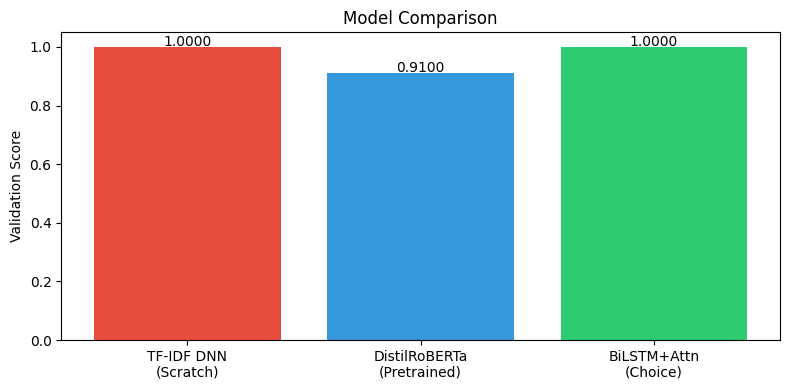

In [83]:

# You can tune: w_tfidf=0.4, w_rob=0.3, w_bilstm=0.3 etc. based on individual val scores
w_tfidf, w_rob, w_bilstm = 0.4, 0.3, 0.3
ensemble_probs = w_tfidf * tfidf_probs + w_rob * rob_probs + w_bilstm * bilstm_probs

# Bar chart comparing the 3 models (placeholder scores — update with your actual val MAP@3)
model_names = ["TF-IDF DNN\n(Scratch)", "DistilRoBERTa\n(Pretrained)", "BiLSTM+Attn\n(Choice)"]
val_scores = [best_map3, best_rob_acc, best_bl_map3]  # replace rob_acc with rob MAP@3 if computed

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(model_names, val_scores, color=["#e74c3c", "#3498db", "#2ecc71"])
ax.set_ylabel("Validation Score"); ax.set_title("Model Comparison")
for bar, score in zip(bars, val_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f"{score:.4f}", ha="center")
plt.tight_layout(); plt.show()

## 8. Generate Submissions (Per-Model + Ensemble)

In [84]:
def make_submission(probs_matrix, filename):
    """Convert (N, 5) probability matrix to MAP@3 submission CSV."""
    top3 = np.argsort(probs_matrix, axis=1)[:, ::-1][:, :3]
    preds = [" ".join(LABELS[i] for i in row) for row in top3]
    sub = pd.DataFrame({"ID": test_df["id"], "Prediction": preds})
    sub.to_csv(filename, index=False)
    print(f"Saved {filename} ({len(sub)} rows)")
    return sub

make_submission(tfidf_probs, "submission_tfidf.csv")
make_submission(rob_probs, "submission_roberta.csv")
make_submission(bilstm_probs, "submission_bilstm.csv")
make_submission(ensemble_probs, "submission_ensemble.csv")

Saved submission_tfidf.csv (500 rows)
Saved submission_roberta.csv (500 rows)
Saved submission_bilstm.csv (500 rows)
Saved submission_ensemble.csv (500 rows)


,ID,Prediction
0,1,A E D
1,2,B D E
2,3,B E D
3,4,E C D
4,5,C A E
...,...,...
495,496,A E D
496,497,C E D
497,498,B E D
498,499,E B D


In [85]:
wandb.finish()
print("All done!")

bilstm/val_map3,▁▇█████████████████████
epoch,▁▁▂▂▂▃▃▁▁▁▁▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇██
roberta/val_acc,▁█
tfidf/val_loss,█▅▃▁▁▁▁
tfidf/val_map3,▁██████
bilstm/val_map3,1
epoch,23
roberta/val_acc,0.91
tfidf/val_loss,0.22452
tfidf/val_map3,1


All done!
